In [1]:
import astropy
import pysas
import paramiko
import os
import tarfile
import subprocess
import shutil
import numpy as np
from collections import defaultdict
from astropy.io.misc import fnunpickle
from astropy.io import fits
from astropy.table import Table, vstack
from astropy.time import Time
import matplotlib.pyplot as plt
import time
import threading
#import keyboard
import pandas as pd
import scipy.optimize as opt
from matplotlib.lines import Line2D

In [2]:
# Define where the ODF are. The odf path has to have ONLY observations
odf_file_path= "/work2/sruedavargas/All_sources_raw"
working_path = "/work2/sruedavargas/Results_all_sources_Sy2"

In [3]:
os.write(1,b"You want the software to run: \n a:automatically \n Software will be executed with predetermined values. No interaction required \n s:semi-automatically \n Software will be executed with predetermined values, but will ask for confirmation to continue \n p:personalized \n Software will ask to enter specific values. Full interaction required \n")

def initial_dec():
    while True:
        key = input("Please press the key 'a', 's', or 'p': ")
        if key.lower() in ['a', 's', 'p']:
            return key.lower()
        else:
            print("Invalid key. Please try again.")


valid_key = initial_dec()

if valid_key == 'a':
    print('Software will run automatically. See you at the end')
elif valid_key == 's':
    print('Software will run semi-automatically. Please be ready to give your approval, otherwise the program will not continue.')
elif valid_key == 'p':
    print('Software will run personalized. Please be ready to enter specific values when needed')


You want the software to run: 
 a:automatically 
 Software will be executed with predetermined values. No interaction required 
 s:semi-automatically 
 Software will be executed with predetermined values, but will ask for confirmation to continue 
 p:personalized 
 Software will ask to enter specific values. Full interaction required 
Please press the key 'a', 's', or 'p': a
Software will run automatically. See you at the end


In [4]:
# Array with all the observations ID

obs_id=[]

for file in os.listdir(odf_file_path):
    name_obs=file.rsplit('.',maxsplit=1)[0]
    obs_id.append(name_obs)


In [ ]:
#Uncompressing the .tar.gz files in a new directory for each observation, and removing the compressed files. 


for file in os.listdir(odf_file_path):
    if file.endswith(".tar.gz"):
        file_path=os.path.join(odf_file_path,file)
        with tarfile.open(file_path, "r:gz", ) as tar:
            tar.extractall(path=os.path.splitext(file_path)[0])
        os.remove(file_path) 

In [ ]:
#Renaming the uncompressed files 


for file1 in os.listdir(odf_file_path):
    if file1.endswith(".tar"):
        file1_path=os.path.join(odf_file_path,file1)
        new_name=os.path.splitext(file1_path)[0]
        obs_id.append(new_name)
        os.rename(file1_path,new_name)
        

In [ ]:
#Uncompressing the .TAR file inside each observation directory
for root, dirs, files in os.walk(odf_file_path):
    for file in files:
        if file.endswith("TAR"):
            file_path=os.path.join(root, file)         
            with tarfile.open(file_path, "r", ) as tar:
                tar.extractall(path=root) 
            os.remove(file_path)

In [5]:
#Starting heasoft and xmm
startsas = 'source /net/konraid/xray/setheasoft.sh'
startsasold = 'source /net/konraid/xray/setxmmsas20.0.0.sh'


subprocess.call(startsas, shell=True)
subprocess.call(startsasold, shell=True)


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .


sasversion:- Executing (routine): sasversion  -w 1 -V 4
sasversion:- sasversion (sasversion-1.3)  [xmmsas_20211130_0941-20.0.0] started:  2023-10-06T15:20:05.000
sasversion:- XMM-Newton SAS release and build information:

SAS release: xmmsas_20211130_0941-20.0.0
Compiled on: Wed Dec  1 09:45:46 CET 2021
Compiled by: xmmsas@trantor
Platform   : Ubuntu20.04

SAS-related environment variables that are set:

SAS_DIR = /net/konraid/xray/xmmsas/xmmsas_20.0.0
SAS_PATH = /ne

0

In [6]:
# Setting the path for the observation files as an environment variable

os.environ['SAS_DIR']='/net/konraid/xray/xmmsas/xmmsas_20.0.0'
os.environ['SAS_PATH']='/net/konraid/xray/xmmsas/xmmsas_20.0.0'
os.environ['SAS_CCFPATH']='/net/konraid/xray/xmmsas/ccf'
os.environ['PGPLOT_DIR']='/net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36/lib'
os.environ['PGPLOT_PATH']='/net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36/lib'

In [ ]:
##### REDUCTION #####

In [ ]:
# Running cifbuild for each of the observation files and obtaining the corresponding ccf.cif for each of them 

odf_prev = []
ccf = []
for file in os.listdir(odf_file_path):
    file_path = os.path.join(odf_file_path, file)
    os.environ['SAS_ODF'] = file_path
    odf_prev.append(file_path)
    cifbuild = '/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/cifbuild'
    subprocess.call([cifbuild], shell=True)
    ccf_file = os.path.join(working_path, 'ccf.cif')
    if os.path.exists(ccf_file):
        new_ccf_file = os.path.join(working_path, f"{file}_ccf.cif")
        os.rename(ccf_file, new_ccf_file)
        ccf.append(new_ccf_file)                 

In [ ]:
# Running odfingest for ODF and CCF files

for (file1, file2) in zip(odf_prev,ccf):    
    os.environ['SAS_ODF'] = file1
    os.environ['SAS_CCF'] = file2
    odfingest = '/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/odfingest'
    subprocess.call([odfingest], shell=True)  

In [ ]:
# Redefining ODF as the summary file created by odfingest

odf = []

for file in os.listdir(working_path):
    if file.endswith(".SAS"):
        file_path = os.path.join(working_path, file)
        os.environ['SAS_ODF'] = file
        odf.append(file_path)

In [ ]:
# Running emproc and epproc


for (file1, file2) in zip(odf,ccf):    
    os.environ['SAS_ODF'] = file1
    os.environ['SAS_CCF'] = file2
    os.environ['PATH'] = '/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin:' + os.environ['PATH']
    emproc = '/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/emproc'
    epproc = '/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/epproc'
    subprocess.call([emproc], shell=True) 
    subprocess.call([epproc], shell=True)

In [7]:
# Moving ImagingEvts.ds files to a new folder called 'products'. 
# If the directory already exists, it removes it and create a new one

products = working_path + '/products'

if os.path.exists(products):
    shutil.rmtree(products)
    os.mkdir(products)
else:
    os.mkdir(products)


for file in os.listdir(working_path):
    if file.endswith("ImagingEvts.ds"):
        file_path=os.path.join(working_path,file)
        shutil.copy(file_path, products)

In [8]:
os.chdir(products)
# Counting how many photon event tables (PET) there are per camera per observation, and warning 
# only about those observations that have more than 2

counts = defaultdict(lambda: defaultdict(int))

for file in os.listdir(products):
    obs_id = file.split('_')[1]
    camera = file.split('_')[2]
    counts[obs_id][camera] += 1
    
print('The following observations may have possibly been interrupted:')
for obs_id, obs_counts in counts.items():
    for camera, count in obs_counts.items():
        if (count >= 2):
            #print (obs_id, camera)
            print (f" {obs_id} \n {camera[1:]}: {count} PET")  

The following observations may have possibly been interrupted:
 0145670101 
 MOS1: 4 PET
 0145670101 
 MOS2: 4 PET
 0145670101 
 PN: 2 PET
 0761220101 
 PN: 2 PET
 0761220101 
 MOS1: 2 PET
 0761220101 
 MOS2: 2 PET
 0795630101 
 MOS2: 2 PET
 0795630101 
 MOS1: 2 PET
 0112830301 
 PN: 2 PET
 0414580101 
 PN: 2 PET
 0414580101 
 MOS1: 2 PET
 0414580101 
 MOS2: 2 PET
 0795630201 
 MOS1: 2 PET
 0795630201 
 MOS2: 2 PET


In [10]:
# For the interrupted observations, create a list with the PET with same OBS_ID and camera

interr = []
for file in os.listdir(products):
    obs_id = file.split('_')[1]
    camera = file.split('_')[2]
    if (counts[obs_id][camera] >= 2):
#         file_path = os.path.join(products, file)
        interr.append(file)

# Handling observations with more than 2 ImagingEvts files
    
df_interr=pd.DataFrame(interr, columns=['file'])


obs_interr=[]
camera_interr=[]
rev_interr=[]

for index,row in df_interr.iterrows():
    
    rev=f"{row['file'].split('_')[0]}"
    obs=f"{row['file'].split('_')[1]}"
    cam=f"{row['file'].split('_')[2]}"

    rev_interr.append(rev)
    obs_interr.append(obs)
    camera_interr.append(cam)
    
df_interr['obs']=obs_interr
df_interr['cam']=camera_interr
df_interr['rev']=rev_interr

df_interr_grouped=df_interr.groupby(['rev','obs','cam'])



files_to_delete=[]
files_to_keep=[]
files_to_delete_1=[]

for name, group in df_interr_grouped:
    RA_PNT=[]
    DEC_PNT=[]
    FILTER=[]
    SUBMODE=[]
    
    def check(list):
        return all(j == list[0] for j in list)
    
    for index,row in group.iterrows():
        
        file_path_i=os.path.join(products, f"{row['file']}")
        hdul_i = fits.open(file_path_i)
        h_i = hdul_i[0].header
        
        RA_PNT.append(h_i['RA_PNT'])
        DEC_PNT.append(h_i['DEC_PNT'])
        FILTER.append(h_i['FILTER'])
        SUBMODE.append(h_i['SUBMODE'])
        
    
    if (check(RA_PNT)==True and check(DEC_PNT)==True and check(FILTER)==True and check(SUBMODE)==True):
        
        
        print (f"RA_PNT, DEC_PNT, FILTER and/or SUBMODE are the same for observation {name[1]} and camera {name[2]}. Merging all PET")
        outfile = f"{name[0]}_{name[1]}_{name[2]}_combined_ImagingEvts.ds"
        
        files_to_merge=[]
        for index,row in group.iterrows():           
            file_path_i=os.path.join(products, f"{row['file']}") 
            files_to_merge.append(file_path_i)
            files_to_delete.append(file_path_i)
            
        merge_path = '/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/merge'
        merge = [f"{merge_path} set1={files_to_merge[0]} set2={files_to_merge[1]} outset={outfile}"]
        subprocess.call(merge, shell=True)
        
        for table in files_to_merge[2:]:
            
            temp_output = 'temp_merged_table.fits'      
            merge1 = [f"{merge_path} set1={outfile} set2={table} outset={temp_output}"]
            subprocess.call(merge1, shell=True)
            
            call(['mv', temp_output, outfile])
            

            
    
    else:
        
        print (f"RA_PNT, DEC_PNT, FILTER and/or SUBMODE are different for observation {name[1]} and camera {name[2]}. Keeping only longest exp time PET")

        duration_files=[]
        
        for index,row in group.iterrows():
            
            file_path_j=os.path.join(products, f"{row['file']}")
            files_to_delete_1.append(file_path_j)
            hdul_j = fits.open(file_path_j)
            h_j = hdul_j[0].header
            
            k = h_j['DATE-OBS']
            l = h_j['DATE-END']
        
            date_start_i = Time(k, format='isot', scale='utc')
            date_stop_i = Time(l, format='isot', scale='utc')
            duration_i = (date_stop_i-date_start_i).sec
            duration_files.append(duration_i)

        group['duration']= duration_files
        longest_df=group[group.duration == group.duration.max()]
        longest_pet=longest_df['file']
        files_to_keep.append(longest_pet)
        
        
files_to_keep_array = np.array(files_to_keep)
files_to_keep_array_1 = files_to_keep_array.flatten()

files_to_keep_path=[]

for file in files_to_keep_array_1:
    files_to_keep_path.append(os.path.join(products,file))
    
    
        

RA_PNT, DEC_PNT, FILTER and/or SUBMODE are the same for observation 0112830301 and camera EPN. Merging all PET


** merge: warning (MergeGeneralWarning), Merged eventsets may result in incorrect results of some downstream tasks - see the task description!


RA_PNT, DEC_PNT, FILTER and/or SUBMODE are different for observation 0145670101 and camera EMOS1. Keeping only longest exp time PET
RA_PNT, DEC_PNT, FILTER and/or SUBMODE are different for observation 0145670101 and camera EMOS2. Keeping only longest exp time PET
RA_PNT, DEC_PNT, FILTER and/or SUBMODE are different for observation 0145670101 and camera EPN. Keeping only longest exp time PET
RA_PNT, DEC_PNT, FILTER and/or SUBMODE are different for observation 0414580101 and camera EMOS1. Keeping only longest exp time PET
RA_PNT, DEC_PNT, FILTER and/or SUBMODE are different for observation 0414580101 and camera EMOS2. Keeping only longest exp time PET
RA_PNT, DEC_PNT, FILTER and/or SUBMODE are different for observation 0414580101 and camera EPN. Keeping only longest exp time PET
RA_PNT, DEC_PNT, FILTER and/or SUBMODE are the same for observation 0761220101 and camera EMOS1. Merging all PET


** merge: warning (MergeGeneralWarning), Merged eventsets may result in incorrect results of some downstream tasks - see the task description!


RA_PNT, DEC_PNT, FILTER and/or SUBMODE are the same for observation 0761220101 and camera EMOS2. Merging all PET


** merge: warning (MergeGeneralWarning), Merged eventsets may result in incorrect results of some downstream tasks - see the task description!


RA_PNT, DEC_PNT, FILTER and/or SUBMODE are the same for observation 0761220101 and camera EPN. Merging all PET


** merge: warning (MergeGeneralWarning), Merged eventsets may result in incorrect results of some downstream tasks - see the task description!


RA_PNT, DEC_PNT, FILTER and/or SUBMODE are different for observation 0795630101 and camera EMOS1. Keeping only longest exp time PET
RA_PNT, DEC_PNT, FILTER and/or SUBMODE are different for observation 0795630101 and camera EMOS2. Keeping only longest exp time PET
RA_PNT, DEC_PNT, FILTER and/or SUBMODE are different for observation 0795630201 and camera EMOS1. Keeping only longest exp time PET
RA_PNT, DEC_PNT, FILTER and/or SUBMODE are different for observation 0795630201 and camera EMOS2. Keeping only longest exp time PET


In [11]:

# For observations with same keywords, removing the original files if the images were merged

for file in files_to_delete:
    file_path=os.path.join(products, file)
    os.remove(file)  
    
# For observations with different keywords, keeping only the longest exposure observations. Deleting the rest


if (len(files_to_keep_path) == 0):
    pass
    
else:
    for file in files_to_delete_1:
        if file in files_to_keep_path:
            files_to_delete_1.remove(file)

    for file in files_to_delete_1  :
        os.remove(file)



In [12]:
# Saving original PET into a list

original_pet = []

for file in os.listdir(products):
    if file.endswith('ImagingEvts.ds'):
        original_pet.append(file)


In [13]:
# Changing directory to the products directory
os.chdir(products)

# Getting first look IMAGES for all the PET
for file in os.listdir(products):
    rev = f"{file.split('_')[0]}"
    obs_id = f"{file.split('_')[1]}"
    cam = f"{file.split('_')[2]}"
    camera = cam.translate({ord('E'):None})
    evselect = [f" /net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/evselect table={file} withimageset=yes imageset=first_look_image_{obs_id}_{camera}.fits xcolumn=X ycolumn=Y imagebinning=imageSize ximagesize=600 yimagesize=600"]
    subprocess.call(evselect, shell=True)

    

** evselect: warning (NoAttrib), The Attribute DLMEAN does not exist in the input event list. No value was copied.
** evselect: warning (NoAttrib), The Attribute DLMAX does not exist in the input event list. No value was copied.


In [14]:
# Merging MOS1 and MOS2 images into MOS
first_look_images=[]


for file in os.listdir(products):
    if file.startswith("first_look_image"):
        first_look_images.append(file)
        

        
#Selecting only the first look images for MOS1 AND MOS2 for the same observation and matching them in a list
mos_match_same=[]
for i in range(len(first_look_images)):
    obs_id_i = f"{first_look_images[i].split('_')[3]}"
    cam_i = f"{first_look_images[i].split('_')[4]}"
    mos_match = [first_look_images[i]]
    for j in range(i+1, len(first_look_images)):
        obs_id_j = f"{first_look_images[j].split('_')[3]}"
        cam_j = f"{first_look_images[j].split('_')[4]}"
        if (obs_id_i==obs_id_j and 'MOS' in cam_i and 'MOS' in cam_j ):
            mos_match.append(first_look_images[j])
    if len(mos_match) > 1:
        mos_match_same.append(tuple(mos_match)) 


# Combining the two images (position 0 and 1 of each element of the list)
for element in mos_match_same:
    obs_id = f"{element[0].split('_')[3]}"
    with open("sfile.sh", "a") as sfl:
        outfile = f"first_look_image_{obs_id}_MOS.fits"
        farith = f"farith {element[0]} {element[1]} {outfile} ADD clobber=yes"
        outtxt ="#!/bin/bash\n\nsource /net/konraid/xray/xraysoft/setheasoft.sh\n{}\n".format(farith)
        sfl.write(outtxt)
    subprocess.call("bash sfile.sh", shell=True)
    first_look_images.append(outfile)


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .

   Removing all previous heasoft entries from LD_LIBRARY_PATH variable

--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, y

In [15]:
# Merging MOS and PN into EPIC

epic = []
for file in (first_look_images):
    if (file.endswith('MOS.fits') or file.endswith('PN.fits')):
        epic.append(file)
        
#Matching PN and MOS images with the the same obs_id

epic_match_same=[]
for i in range(len(epic)):
    obs_id_i = f"{epic[i].split('_')[3]}"
    cam_i = f"{epic[i].split('_')[4]}"
    epic_match = [epic[i]]
    for j in range(i+1, len(epic)):
        obs_id_j = f"{epic[j].split('_')[3]}"
        cam_j = f"{epic[j].split('_')[4]}"
        if (obs_id_i==obs_id_j):
            epic_match.append(epic[j])
    if len(epic_match) > 1:
        epic_match_same.append(tuple(epic_match)) 


# Combining the two images (position 0 and 1 of each element of the list)
for element in epic_match_same:
    obs_id = f"{element[0].split('_')[3]}"
    with open("sfile1.sh", "a") as sfl:
        outfile1 = f"first_look_image_{obs_id}_EPIC.fits"
        farith = f"farith {element[0]} {element[1]} {outfile1} ADD clobber=yes"
        outtxt1 ="#!/bin/bash\n\nsource /net/konraid/xray/xraysoft/setheasoft.sh\n{}\n".format(farith)
        sfl.write(outtxt1)
    subprocess.call("bash sfile1.sh", shell=True)
    first_look_images.append(outfile1)


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .

   Removing all previous heasoft entries from LD_LIBRARY_PATH variable

--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, y

In [16]:
# Distributing images for different cameras

mos_img=[]
pn_img=[]
epic_img=[]


for image in first_look_images:
    if image.endswith('MOS.ds'):
        mos_img.append(image)
    elif image.endswith('PN.ds'):
        pn_img.append(image)
    elif image.endswith('EPIC.ds'):
        epic_img.append(image)

In [17]:
# Removal of some background noise from data by creating ligth curves WITH source.

# Filtering high energy with source and creating high energy light curve

for file in original_pet:
    obs_id = f"{file.split('_')[1]}"
    cam = f"{file.split('_')[2]}"
    camera = cam.translate({ord('E'):None})
    letter = camera[0]
    evselect = [f" /net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/evselect table={file} expression='((#XMMEA_E{letter} && PI in [10000:15000]) && (PATTERN<=4) && (FLAG == 0))' filteredset=background_pet_{obs_id}_{camera}_highE.fits filtertype=expression keepfilteroutput=yes updateexposure=yes filterexposure=yes maketimecolumn=yes timecolumn=TIME timebinsize=100 makeratecolumn=yes withrateset=yes rateset=background_lc_{obs_id}_{camera}_highE.fits"]
    subprocess.call(evselect, shell=True)

highE_pet = []
for file in os.listdir(products):
    if file.startswith('background_pet') and file.endswith('highE.fits'):
        highE_pet.append(file)
        
        
# Creating image for previously filtered data
        
for file in highE_pet:
    obs_id = f"{file.split('_')[1]}"
    cam = f"{file.split('_')[2]}"
    camera = cam.translate({ord('E'):None})
    evselect = [f" /net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/evselect table={file} withimageset=yes imageset=background_image_{obs_id}_{camera}_highE.fits xcolumn=X ycolumn=Y imagebinning=imageSize ximagesize=600 yimagesize=600"]
    subprocess.call(evselect, shell=True)


** evselect: warning (NoAttrib), The Attribute DLMEAN does not exist in the input event list. No value was copied.
** evselect: warning (NoAttrib), The Attribute DLMAX does not exist in the input event list. No value was copied.
** evselect: warning (NoAttrib), The Attribute DLMEAN does not exist in the input event list. No value was copied.
** evselect: warning (NoAttrib), The Attribute DLMAX does not exist in the input event list. No value was copied.


In [18]:
# Filtering low energy with source and creating low energy light curve


for file in original_pet:
    obs_id = f"{file.split('_')[1]}"
    cam = f"{file.split('_')[2]}"
    camera = cam.translate({ord('E'):None})
    letter = camera[0]
    evselect = [f" /net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/evselect table={file} expression='((#XMMEA_E{letter} && PI in [100:500]) && (PATTERN<=4) && (FLAG == 0))' filteredset=background_pet_{obs_id}_{camera}_lowE.fits filtertype=expression keepfilteroutput=yes updateexposure=yes filterexposure=yes maketimecolumn=yes timecolumn=TIME timebinsize=100 makeratecolumn=yes withrateset=yes rateset=background_lc_{obs_id}_{camera}_lowE.fits"]
    subprocess.call(evselect, shell=True)

lowE_pet = []
for file in os.listdir(products):
    if file.startswith('background_pet') and file.endswith('lowE.fits'):
        lowE_pet.append(file)
        
        
# Creating image for previously filtered data
        
for file in lowE_pet:
    obs_id = f"{file.split('_')[1]}"
    cam = f"{file.split('_')[2]}"
    camera = cam.translate({ord('E'):None})
    evselect = [f" /net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/evselect table={file} withimageset=yes imageset=background_image_{obs_id}_{camera}_lowE.fits xcolumn=X ycolumn=Y imagebinning=imageSize ximagesize=600 yimagesize=600"]
    subprocess.call(evselect, shell=True)


** evselect: warning (NoAttrib), The Attribute DLMEAN does not exist in the input event list. No value was copied.
** evselect: warning (NoAttrib), The Attribute DLMAX does not exist in the input event list. No value was copied.
** evselect: warning (NoAttrib), The Attribute DLMEAN does not exist in the input event list. No value was copied.
** evselect: warning (NoAttrib), The Attribute DLMAX does not exist in the input event list. No value was copied.


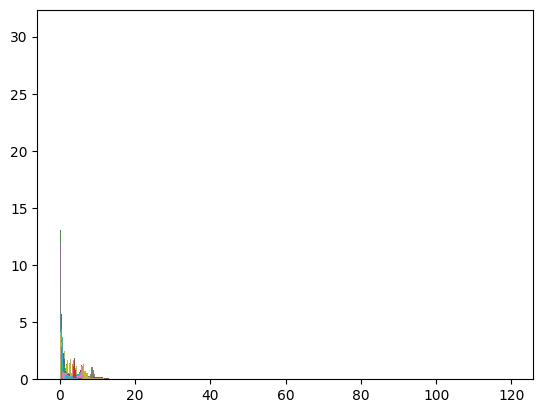

In [19]:
# Creating GTI for each of the light curves created previously. 
 

background_lc = []

for file in os.listdir(products):
    if file.startswith('background_lc'):
        background_lc.append(file)
        

def process_file(file):
    obs_id = f"{file.split('_')[2]}"
    camera = f"{file.split('_')[3]}"
    en = os.path.splitext(file)[0]
    energy = f"{en.split('_')[4]}"

    with fits.open(file) as f:
        data = f[1].data
        rate = data.field(0)
        time = data.field(2)

        if valid_key == 'a' or valid_key == 's':
            hist = plt.hist(rate, density=True, bins=14)
            max_bin_index = hist[0].argmax()
            bins = hist[1]
            x_values = [(bins[i] + bins[i+1]) / 2 for i in range(len(bins) - 1)]
            max_x = x_values[max_bin_index]

            # Creating conservative GTI.
            cons_val = 2 * max_x
            tabgtigen_cons = f"/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/tabgtigen table={file} gtiset={obs_id}_{camera}_gti_{energy}_cons.fits expression='RATE<{cons_val}'"
            subprocess.call(tabgtigen_cons, shell=True)

            # Creating relaxed GTI.
            rel_val = 5 * max_x
            tabgtigen_rel = f"/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/tabgtigen table={file} gtiset={obs_id}_{camera}_gti_{energy}_rel.fits expression='RATE<{rel_val}'"
            subprocess.call(tabgtigen_rel, shell=True)

        elif valid_key == 'p':
            fig, ax = plt.subplots()  
            ax.plot(time, rate)
            ax.set_xlabel("TIME")
            ax.set_ylabel("RATE")
            ax.set_title(f"{file}")
            plt.pause(0.1)
            
            
            os.write(1, b'Define conservative and relaxed values for ' + file.encode() + b'\n')
            #print('Define conservative and relaxed values for ' + file)
            cons_val_f = input('Conservative: ')
            rel_val_f = input('Relaxed: ')

            cons_val = float(cons_val_f)
            rel_val = float(rel_val_f)

            # Save the values chosen by the user for the current file
            gti_user_choices[file] = {'conservative': cons_val, 'relaxed': rel_val}

            # Creating conservative GTI.
            tabgtigen_cons = f"/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/tabgtigen table={file} gtiset={obs_id}_{camera}_gti_{energy}_cons.fits expression='RATE<{cons_val}'"
            subprocess.call(tabgtigen_cons, shell=True)

            # Creating relaxed GTI.
            tabgtigen_rel = f"/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/tabgtigen table={file} gtiset={obs_id}_{camera}_gti_{energy}_rel.fits expression='RATE<{rel_val}'"
            subprocess.call(tabgtigen_rel, shell=True)


# Dictionary to store user choices for each file
gti_user_choices = {}

for file in background_lc:
    process_file(file)

# Print the user choices for each file
if(valid_key == 'p'):
    print("User choices:")
    
for file, choices in gti_user_choices.items():
    print(f"{file}: Conservative={choices['conservative']}, Relaxed={choices['relaxed']}")

   

In [20]:
# Merging low and high energy GTI 
### CONSERVATIVE

gti_cons = []

for file in os.listdir(products):
    if file.endswith('cons.fits') and 'gti' in file:
        gti_cons.append(file)

        
same_gti_cons = []

for i in range(len(gti_cons)):
    obs_id_i = f"{gti_cons[i].split('_')[0]}"
    camera_i = f"{gti_cons[i].split('_')[1]}"
    matching_files = [gti_cons[i]]
    for j in range(i+1, len(gti_cons)):
        obs_id_j = f"{gti_cons[j].split('_')[0]}"
        camera_j = f"{gti_cons[j].split('_')[1]}"
        if (obs_id_i == obs_id_j and camera_i == camera_j):
            matching_files.append(gti_cons[j])
    if len(matching_files) > 1:
        same_gti_cons.append(tuple(matching_files))
    

for element in same_gti_cons:
    obs_id = f"{element[0].split('_')[0]}"
    camera = f"{element[0].split('_')[1]}"
    
    outfile = f"{obs_id}_{camera}_gti_combined_cons.fits"
    table1 = element[0]
    table2 = element[1]
    
    gtimerge_path = '/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/gtimerge'
    gtimerge = [f"{gtimerge_path} tables='{table1} {table2}' gtitable={outfile} mergemode=and"]
    subprocess.call(gtimerge, shell=True)
    
    
### RELAXED



gti_rel = []

for file in os.listdir(products):
    if file.endswith('rel.fits') and 'gti' in file:
        gti_rel.append(file)

        
same_gti_rel = []

for i in range(len(gti_rel)):
    obs_id_i = f"{gti_rel[i].split('_')[0]}"
    camera_i = f"{gti_rel[i].split('_')[1]}"
    matching_files = [gti_rel[i]]
    for j in range(i+1, len(gti_rel)):
        obs_id_j = f"{gti_rel[j].split('_')[0]}"
        camera_j = f"{gti_rel[j].split('_')[1]}"
        if (obs_id_i == obs_id_j and camera_i == camera_j):
            matching_files.append(gti_rel[j])
    if len(matching_files) > 1:
        same_gti_rel.append(tuple(matching_files))
    

for element in same_gti_rel:
    obs_id = f"{element[0].split('_')[0]}"
    camera = f"{element[0].split('_')[1]}"
    
    outfile = f"{obs_id}_{camera}_gti_combined_rel.fits"
    table1 = element[0]
    table2 = element[1]
    
    gtimerge_path = '/net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/gtimerge'
    gtimerge = [f"{gtimerge_path} tables='{table1} {table2}' gtitable={outfile} mergemode=and"]
    subprocess.call(gtimerge, shell=True)
           

In [21]:
# CONSERVATIVE RATE

# Filtering the files to match original file, low energy gti conservative and high energy conservative

gti_highE_cons = []

for file in os.listdir(products):
    if file.endswith('highE_cons.fits'):
        gti_highE_cons.append(file)
        
gti_lowE_cons = []

for file in os.listdir(products):
    if file.endswith('lowE_cons.fits'):
        gti_lowE_cons.append(file)

        
gti_input_cons=[]


for file in original_pet:
    obs_id_or = f"{file.split('_')[1]}"
    cam = f"{file.split('_')[2]}"
    camera_or = cam.translate({ord('E'):None})
    row = [file]
    for file1 in gti_highE_cons:
        obs_id_highE = f"{file1.split('_')[0]}"
        camera_highE = f"{file1.split('_')[1]}"
        if obs_id_or==obs_id_highE and camera_or==camera_highE:
            row.append(file1)
            for file2 in gti_lowE_cons:
                obs_id_lowE = f"{file2.split('_')[0]}"
                camera_lowE = f"{file2.split('_')[1]}"
                if obs_id_or==obs_id_lowE and camera_or==camera_lowE:
                    row.append(file2)
    if len(row) > 1:
        gti_input_cons.append(row)
        

# Filtering the original PET with the low and high energy conservative gti

for element in gti_input_cons:
    table = element[0]
    highE = element[1]
    lowE = element[2]
    obs_id = f"{highE.split('_')[0]}"
    camera = f"{highE.split('_')[1]}"
    letter = camera[0]
    evselect = [f" /net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/evselect table={table} withfilteredset=yes filteredset=filtered_{obs_id}_{camera}_0.2_12keV_cons.fits keepfilteroutput=yes destruct=yes expression='(#XMMEA_E{letter} && gti({lowE}:STDGTI,TIME) && gti({highE}:STDGTI,TIME) && (PI in [200:12000]) && (PATTERN<=12) && (FLAG == 0))'"]
    subprocess.call(evselect, shell=True)
    
filtered_cons = []
for file in os.listdir(products):
    if file.startswith('filtered') and file.endswith('cons.fits'):
        filtered_cons.append(file)
        
# Creating filtered (cleaned) image with the conservative rate

for file in filtered_cons:
    obs_id = f"{file.split('_')[1]}"
    cam = f"{file.split('_')[2]}"
    camera = cam.translate({ord('E'):None})
    evselect = [f" /net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/evselect table={file} withimageset=yes imageset=image_{obs_id}_{camera}_0.2_12keV_cons.fits xcolumn=X ycolumn=Y imagebinning=binSize ximagebinsize=80 yimagebinsize=80"]
    subprocess.call(evselect, shell=True)
   

** evselect: warning (NoTargetOntime), Ontime for target CCD (number 1) is not available. Setting ONTIME to zero.
** evselect: warning (NoTargetLivetime), Live time for target CCD (number 1) is not available. Setting LIVETIME to zero.
** evselect: warning (NoTargetOntime), Ontime for target CCD (number 1) is not available. Setting ONTIME to zero.
** evselect: warning (NoTargetLivetime), Live time for target CCD (number 1) is not available. Setting LIVETIME to zero.
** evselect: warning (NoAttrib), The Attribute DLMEAN does not exist in the input event list. No value was copied.
** evselect: warning (NoAttrib), The Attribute DLMAX does not exist in the input event list. No value was copied.


In [22]:
# RELAXED RATE

# Filtering the files to match original file, low energy gti relaxed and high energy relaxed

gti_highE_rel = []

for file in os.listdir(products):
    if file.endswith('highE_rel.fits'):
        gti_highE_rel.append(file)
        
gti_lowE_rel = []

for file in os.listdir(products):
    if file.endswith('lowE_rel.fits'):
        gti_lowE_rel.append(file)
        

        
gti_input_rel=[]


for file in original_pet:
    obs_id_or = f"{file.split('_')[1]}"
    cam = f"{file.split('_')[2]}"
    camera_or = cam.translate({ord('E'):None})
    row = [file]
    for file1 in gti_highE_rel:
        obs_id_highE = f"{file1.split('_')[0]}"
        camera_highE = f"{file1.split('_')[1]}"
        if obs_id_or==obs_id_highE and camera_or==camera_highE:
            row.append(file1)
            for file2 in gti_lowE_rel:
                obs_id_lowE = f"{file2.split('_')[0]}"
                camera_lowE = f"{file2.split('_')[1]}"
                if obs_id_or==obs_id_lowE and camera_or==camera_lowE:
                    row.append(file2)
    if len(row) > 1:
        gti_input_rel.append(row)
        

# Filtering the original PET with the low and high energy conservative gti

for element in gti_input_rel:
    table = element[0]
    highE = element[1]
    lowE = element[2]
    obs_id = f"{highE.split('_')[0]}"
    camera = f"{highE.split('_')[1]}"
    letter = camera[0]
    evselect = [f" /net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/evselect table={table} withfilteredset=yes filteredset=filtered_{obs_id}_{camera}_0.2_12keV_rel.fits keepfilteroutput=yes destruct=yes expression='(#XMMEA_E{letter} && gti({lowE}:STDGTI,TIME) && gti({highE}:STDGTI,TIME) && (PI in [200:12000]) && (PATTERN<=12) && (FLAG == 0))'"]
    subprocess.call(evselect, shell=True)
    
filtered_rel = []
for file in os.listdir(products):
    if file.startswith('filtered') and file.endswith('rel.fits'):
        filtered_rel.append(file)
        
# Creating filtered (cleaned) image with the relaxed rate

for file in filtered_rel:
    obs_id = f"{file.split('_')[1]}"
    cam = f"{file.split('_')[2]}"
    camera = cam.translate({ord('E'):None})
    evselect = [f" /net/konraid/xray/xmmsas/xmmsas_20.0.0/bin/evselect table={file} withimageset=yes imageset=image_{obs_id}_{camera}_0.2_12keV_rel.fits xcolumn=X ycolumn=Y imagebinning=binSize ximagebinsize=80 yimagebinsize=80"]
    subprocess.call(evselect, shell=True)

** evselect: warning (NoTargetOntime), Ontime for target CCD (number 1) is not available. Setting ONTIME to zero.
** evselect: warning (NoTargetLivetime), Live time for target CCD (number 1) is not available. Setting LIVETIME to zero.
** evselect: warning (NoTargetOntime), Ontime for target CCD (number 1) is not available. Setting ONTIME to zero.
** evselect: warning (NoTargetLivetime), Live time for target CCD (number 1) is not available. Setting LIVETIME to zero.
** evselect: warning (NoAttrib), The Attribute DLMEAN does not exist in the input event list. No value was copied.
** evselect: warning (NoAttrib), The Attribute DLMAX does not exist in the input event list. No value was copied.


In [23]:

# Getting final images for MOS and EPIC 

### CONSERVATIVE

# Merging MOS1 and MOS2 images into MOS

images_cons=[]



for file in os.listdir(products):
    if file.startswith('image') and file.endswith('cons.fits'):
        images_cons.append(file)

        
#Selecting only the first look images for MOS1 AND MOS2 for the same observation and matching them in a list

mos_match_same_images_cons=[]

for i in range(len(images_cons)):
    obs_id_i = f"{images_cons[i].split('_')[1]}"
    cam_i = f"{images_cons[i].split('_')[2]}"
    mos_match = [images_cons[i]]
    for j in range(i+1, len(images_cons)):
        obs_id_j = f"{images_cons[j].split('_')[1]}"
        cam_j = f"{images_cons[j].split('_')[2]}"
        if (obs_id_i==obs_id_j and 'MOS' in cam_i and 'MOS' in cam_j ):
            mos_match.append(images_cons[j])
    if len(mos_match) > 1:
        mos_match_same_images_cons.append(tuple(mos_match)) 


# Combining the two images (MOS1 and MOS2) (position 0 and 1 of each element of the list)
for element in mos_match_same_images_cons:
    obs_id = f"{element[0].split('_')[1]}"
    with open("sfile2.sh", "a") as sfl:
        outfile = f"image_{obs_id}_MOS_0.2_12keV_cons.fits"
        farith = f"farith {element[0]} {element[1]} {outfile} ADD clobber=yes"
        outtxt ="#!/bin/bash\n\nsource /net/konraid/xray/xraysoft/setheasoft.sh\n{}\n".format(farith)
        sfl.write(outtxt)
    subprocess.call("bash sfile2.sh", shell=True)
    images_cons.append(outfile)
    
# Merging MOS and PN into EPIC

epic_images_cons = []

for file in (images_cons):
    if file.endswith('MOS_0.2_12keV_cons.fits') or file.endswith('PN_0.2_12keV_cons.fits'):
        epic_images_cons.append(file)



# #Matching PN and MOS images with the the same obs_id

epic_match_same_images_cons=[]
for i in range(len(epic_images_cons)):
    obs_id_i = f"{epic_images_cons[i].split('_')[1]}"
    cam_i = f"{epic_images_cons[i].split('_')[2]}"
    epic_match_images = [epic_images_cons[i]]
    for j in range(i+1, len(epic_images_cons)):
        obs_id_j = f"{epic_images_cons[j].split('_')[1]}"
        cam_j = f"{epic_images_cons[j].split('_')[2]}"
        if (obs_id_i==obs_id_j):
            epic_match_images.append(epic_images_cons[j])
    if len(epic_match_images) > 1:
        epic_match_same_images_cons.append(tuple(epic_match_images)) 


        

# # Combining the two images (position 0 and 1 of each element of the list)

for element in epic_match_same_images_cons:
    obs_id = f"{element[0].split('_')[1]}"
    with open("sfile3.sh", "a") as sfl:
        outfile1 = f"image_{obs_id}_EPIC_0.2_12keV_cons.fits"
        farith = f"farith {element[0]} {element[1]} {outfile1} ADD clobber=yes"
        outtxt1 ="#!/bin/bash\n\nsource /net/konraid/xray/xraysoft/setheasoft.sh\n{}\n".format(farith)
        sfl.write(outtxt1)
    subprocess.call("bash sfile3.sh", shell=True)
    images_cons.append(outfile1)   
    



--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .

   Removing all previous heasoft entries from LD_LIBRARY_PATH variable

--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, y

In [24]:
### RELAXED

# Merging MOS1 and MOS2 images into MOS


images_rel=[]



for file in os.listdir(products):
    if file.startswith('image') and file.endswith('rel.fits'):
        images_rel.append(file)

        
#Selecting only the first look images for MOS1 AND MOS2 for the same observation and matching them in a list

mos_match_same_images_rel=[]

for i in range(len(images_rel)):
    obs_id_i = f"{images_rel[i].split('_')[1]}"
    cam_i = f"{images_rel[i].split('_')[2]}"
    mos_match = [images_rel[i]]
    for j in range(i+1, len(images_rel)):
        obs_id_j = f"{images_rel[j].split('_')[1]}"
        cam_j = f"{images_rel[j].split('_')[2]}"
        if (obs_id_i==obs_id_j and 'MOS' in cam_i and 'MOS' in cam_j ):
            mos_match.append(images_rel[j])
    if len(mos_match) > 1:
        mos_match_same_images_rel.append(tuple(mos_match)) 


# Combining the two images (MOS1 and MOS2) (position 0 and 1 of each element of the list)
for element in mos_match_same_images_rel:
    obs_id = f"{element[0].split('_')[1]}"
    with open("sfile4.sh", "a") as sfl:
        outfile = f"image_{obs_id}_MOS_0.2_12keV_rel.fits"
        farith = f"farith {element[0]} {element[1]} {outfile} ADD clobber=yes"
        outtxt ="#!/bin/bash\n\nsource /net/konraid/xray/xraysoft/setheasoft.sh\n{}\n".format(farith)
        sfl.write(outtxt)
    subprocess.call("bash sfile4.sh", shell=True)
    images_rel.append(outfile)
    
# Merging MOS and PN into EPIC

epic_images_rel = []

for file in (images_rel):
    if file.endswith('MOS_0.2_12keV_rel.fits') or file.endswith('PN_0.2_12keV_rel.fits'):
        epic_images_rel.append(file)



# #Matching PN and MOS images with the the same obs_id

epic_match_same_images_rel=[]
for i in range(len(epic_images_rel)):
    obs_id_i = f"{epic_images_rel[i].split('_')[1]}"
    cam_i = f"{epic_images_rel[i].split('_')[2]}"
    epic_match_images = [epic_images_rel[i]]
    for j in range(i+1, len(epic_images_rel)):
        obs_id_j = f"{epic_images_rel[j].split('_')[1]}"
        cam_j = f"{epic_images_rel[j].split('_')[2]}"
        if (obs_id_i==obs_id_j):
            epic_match_images.append(epic_images_rel[j])
    if len(epic_match_images) > 1:
        epic_match_same_images_rel.append(tuple(epic_match_images)) 


# # Combining the two images (position 0 and 1 of each element of the list)

for element in epic_match_same_images_rel:
    obs_id = f"{element[0].split('_')[1]}"
    with open("sfile5.sh", "a") as sfl:
        outfile1 = f"image_{obs_id}_EPIC_0.2_12keV_rel.fits"
        farith = f"farith {element[0]} {element[1]} {outfile1} ADD clobber=yes"
        outtxt1 ="#!/bin/bash\n\nsource /net/konraid/xray/xraysoft/setheasoft.sh\n{}\n".format(farith)
        sfl.write(outtxt1)
    subprocess.call("bash sfile5.sh", shell=True)
    images_rel.append(outfile1)   


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .

   Removing all previous heasoft entries from LD_LIBRARY_PATH variable

--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, you may need to set:  export XPA_METHOD=local .
If you prefer to get rid of the virtual python environment, type: deactivate .


--- HEASOFT environment has been initialized using /net/konraid/xray/heasoft/heasoft-6.31/x86_64-pc-linux-gnu-libc2.36 .

In addition, y

In [25]:
# From all the obtained files, matching only the original image, and the cleaned one 
# with conservative and relaxed value

img_original=[]
img_cleaned_cons=[]
img_cleaned_rel=[]


def comparison(file):
    if file.startswith('first_look_image') and 'EPIC' in file: 
        img_original.append(file)
    if file.startswith('image') and file.endswith('0.2_12keV_cons.fits') and 'EPIC' in file:
        img_cleaned_cons.append(file)
    if file.startswith('image') and file.endswith('0.2_12keV_rel.fits') and 'EPIC' in file:
        img_cleaned_rel.append(file)
        
        
        
for file in os.listdir(products):
    comparison(file)
    
    
initial_final=[]


for file in img_original:
    obs_id_or = f"{file.split('_')[3]}"
    cam_or = os.path.splitext(file)[0]
    camera_or = cam_or.split('_')[4]
    row = [file]
    for file1 in img_cleaned_cons:
        obs_id_cons = f"{file1.split('_')[1]}"
        camera_cons = f"{file1.split('_')[2]}"
        if obs_id_or==obs_id_cons and camera_or==camera_cons:
            row.append(file1)
            for file2 in img_cleaned_rel:
                obs_id_rel = f"{file2.split('_')[1]}"
                camera_rel = f"{file2.split('_')[2]}"
                if obs_id_or==obs_id_rel and camera_or==camera_rel:
                    row.append(file2)
    if len(row) > 1:
        initial_final.append(row)


In [26]:
os.chdir(products)

# Filtered set of photon event tables 

filtered_pet=[]

for file in os.listdir(products):
    if file.startswith('filtered'):
        filtered_pet.append(file)
        
%store filtered_pet



Stored 'filtered_pet' (list)


In [27]:
# Checking if the central CCD was switched off when the observation was taken
# If LIVETIME=0, then the whole observation is removed and not taken into account. The whole observation includes the
# 3 cameras, even if in one of them the LIVETIME=!0

prob_chip_obid=[]

for file in filtered_pet:
    hdul = fits.open(file)
    h = hdul[1].header
    livetime = h['LIVETIME']
    if livetime==0:
        obs_id = f"{file.split('_')[1]}"
        prob_chip_obid.append(obs_id)
        filtered_pet.remove(file)
        
%store prob_chip_obid

        
os.write(1, b'In the following observations the chip may have been switched off. Observations will not be taken into account')

for file in filtered_pet:
    obs_id = f"{file.split('_')[1]}"
    if obs_id in prob_chip_obid:
        os.write(1, b'\n' + obs_id.encode() + b'\n')
        filtered_pet.remove(file)
 


Stored 'prob_chip_obid' (list)
In the following observations the chip may have been switched off. Observations will not be taken into account
0880550401

0880550401


In [28]:
# USER INTERACTION AFTER CLEANED IMAGES AND FILTERED PET CREATED

#Showing initial image and final image with conservative and relaxed GTI

if valid_key == 'a':
    os.write(1, b'Cleaned images for each observation and camera obtained')
elif valid_key == 's' or valid_key == 'p':
    for elemnt in initial_final:
        first_look_img = elemnt[0]
        cleaned_cons_img = elemnt[1]
        cleaned_rel_img = elemnt[2]
        ds9 = [f"ds9 -tile -geometry 1000x1000 -scale mode 99.85 -scale linear -zoom to fit -cmap heat {first_look_img} {cleaned_cons_img} {cleaned_rel_img}"]
        subprocess.call(ds9, shell=True)  

Cleaned images for each observation and camera obtained

In [29]:
# Asking user if all images are ok

if valid_key == 's' or valid_key == 'p':
    os.write(1, b'All images looking ok? \n y: Yes. Continue to spectra \n n: No. Problem with 1 or more observations')
    x = input()
    
# If user agrees to all images, program continues. If there is one problematic observation, it is removed.

if valid_key == 's' or valid_key == 'p':

    if x.lower()=='y':
        os.write(1, b'Good. Let\'s continue')
    elif x.lower()=='n':
        os.write(1, b'Please enter the obs_id of problematic(s) observations separated by a \',\'. Those observations will not be used \n ')
        obs_id_choice=input()


        probl_obs_id=obs_id_choice.split(',')


        for pet in filtered_pet:
            obs_id = f"{pet.split('_')[1]}"
            for obs in probl_obs_id:
                if obs_id==obs:
                    filtered_pet.remove(pet)
